<img src=https://courseware.decoded.com/images/decoded/logo-decoded.png align=left width=100px/>

# M08 ML Classification Capstone Template
---
<small>© 2026 Decoded Limited. All rights reserved. Website: https://decoded.com </small>

In this notebook we provide a guide/template that you can use for your capstone. This template is SPECIFICALLY for Binary Classification refer to the other templates if your tasks is Regression or Time Series

In [74]:
# Install dependencies (uncomment if running for the first time in this environment)
#pip install ydata-profiling pycaret
#pip install optuna

## 0. Loading Your Data

In [75]:
import pandas as pd
import numpy as np
from ydata_profiling import ProfileReport
import matplotlib.pyplot as plt
import seaborn as sns
pd.reset_option("display.max_rows")
pd.set_option("display.max_columns", None)
%matplotlib inline

In [76]:
#Loading the dataset
from sklearn.datasets import load_diabetes
df = load_diabetes(as_frame=True).frame

#### What does this dataset contain?

## 1. Loading the Data
We will load and inspect the head

In [77]:
df.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


Identitfy and inspect the Regression Target (the thing we wish to predict)

<Axes: >

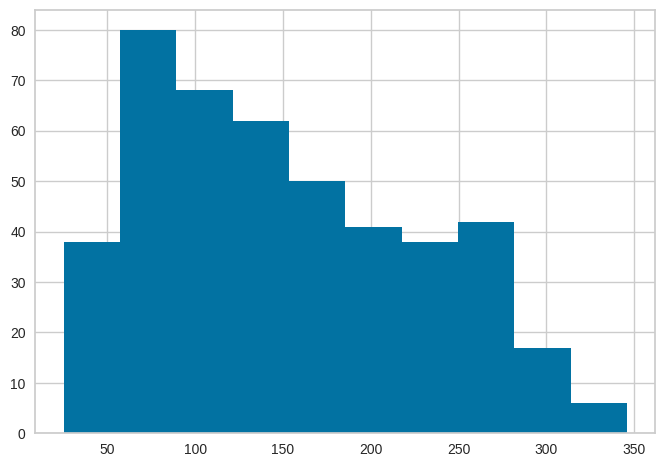

In [78]:
df["target"].hist()

## 2. Generating the Profile Reports
Instead of writing dozens of `df.describe()` and `df.hist()` commands, we pass our dataframes into `ProfileReport`.

*Note: To save memory in the notebook, we will display the ex report interactively, but export the Insurance report as an HTML file.*

In [79]:
# --- Profile the Insurance Dataset ---
ex_profile = ProfileReport(df, title="EDA Report Regression", explorative=True)
ex_profile.to_notebook_iframe()

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 11/11 [00:00<00:00, 193854.39it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Use the overview pane the first pane to guide our data checks

### 0. Data Familiarization (Sanity Check)

In [80]:
# Shape of data (rows, columns)
df.shape

(442, 11)

Comments on shape:

Potential consideration:

What is the shape of the data?
do you have a small dataset?

In [81]:
df.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


comments on the head:

potential consideration:

What does a sample look like?
- Reveals structure and obvious issues
- Identify target, IDs, feature types

In [82]:
# Data types
df.dtypes

age       float64
sex       float64
bmi       float64
bp        float64
s1        float64
s2        float64
s3        float64
s4        float64
s5        float64
s6        float64
target    float64
dtype: object

comments on dtypes:


potential considerations:

Are data types correct?
-  Affects all downstream processing
- Fix dtypes later on, separate feature groups

do we have outliers/anomalies?

In [83]:
# Data types
df.describe()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
count,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,442.000000
mean,-2.511817e-19,1.230790e-17,-2.245564e-16,-4.797570e-17,-1.381499e-17,3.918434e-17,-5.777179e-18,-9.042540e-18,9.293722e-17,1.130318e-17,152.133484
std,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,77.093005
min,-1.072256e-01,-4.464164e-02,-9.027530e-02,-1.123988e-01,-1.267807e-01,-1.156131e-01,-1.023071e-01,-7.639450e-02,-1.260971e-01,-1.377672e-01,25.000000
25%,-3.729927e-02,-4.464164e-02,-3.422907e-02,-3.665608e-02,-3.424784e-02,-3.035840e-02,-3.511716e-02,-3.949338e-02,-3.324559e-02,-3.317903e-02,87.000000
50%,5.383060e-03,-4.464164e-02,-7.283766e-03,-5.670422e-03,-4.320866e-03,-3.819065e-03,-6.584468e-03,-2.592262e-03,-1.947171e-03,-1.077698e-03,140.500000
75%,3.807591e-02,5.068012e-02,3.124802e-02,3.564379e-02,2.835801e-02,2.984439e-02,2.931150e-02,3.430886e-02,3.243232e-02,2.791705e-02,211.500000
max,1.107267e-01,5.068012e-02,1.705552e-01,1.320436e-01,1.539137e-01,1.987880e-01,1.811791e-01,1.852344e-01,1.335973e-01,1.356118e-01,346.000000


comments on values considering the min and maxes in particular:

any potential actions:

Any obvious anomalies?
- Early detection of data issues
- Flag problems for deeper analysis later

## EDA informed Considerations

for this one select the target variable from the drop down list

### 1. Look at the Target Variable

Missing target values?

In [84]:
# 4. Check missing target values (code)
df["target"].isnull().sum()

0

comments:

actions:

- Invalid training samples
- ✅ Drop or fix before modeling

lets double check the distribution of the target

<Axes: >

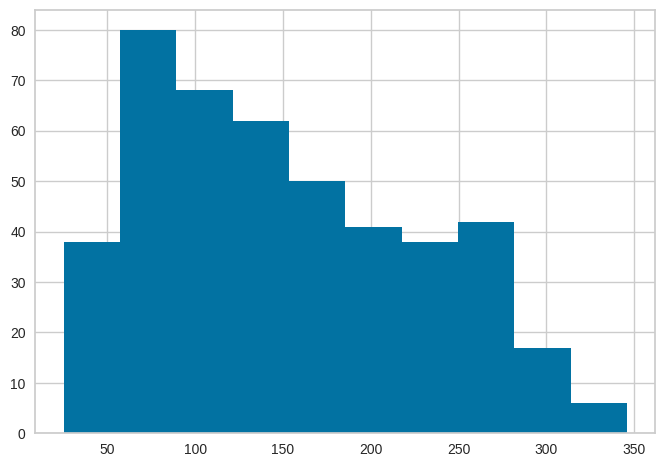

In [85]:
df["target"].hist()

comment:

lets quantity the skewness:

In [86]:
df["target"].skew()

0.44056293407014124

comments:

considerations:

- Will my model be biased toward lower/higher values?
- Do I need transformation for:
- Linear regression assumptions
- Better error distribution

### 2. Data Quality

are there missing values missing values/rows?

In [89]:
# Missing values (proportion)
df.isnull().sum().sort_values(ascending=False)

age       0
sex       0
bmi       0
bp        0
s1        0
s2        0
s3        0
s4        0
s5        0
s6        0
target    0
dtype: int64

comment:

potential actions:

How much missing data is there?

Low (<5%)
→ Likely negligible, simple imputation is fine
Moderate (5–30%)

→ Requires thought; may impact model performance
High (>30–50%)

→ Risky feature, consider:

Dropping
Using missing indicator
Special imputation strategies

Are there constant / near-constant columns?

In [90]:
constant_cols = [col for col in df.columns if df[col].nunique() <= 1]

In [19]:
constant_cols

[]

comments:

potential actions:

No predictive value might, drop later in preprocessing

Are there Duplicate rows?

In [20]:
# Count duplicates
df.duplicated().sum()

0

comments:

action:

*remember* we can drop duplicates before train/test split

drop duplicates:

In [21]:
# Drop duplicates
df = df.drop_duplicates()

In [22]:
df.shape

(442, 11)

comment on new shape after drop

In [23]:
# lets check cardinality (amount of groups in our column)
df.select_dtypes(include=['object','category']).nunique().sort_values(ascending=False)

Series([], dtype: float64)

comments:

actions to consider:

High cardinality (many unique values):

- Potential issues:
- Harder to model
- Risk of overfitting
- Encoding becomes complex

Low cardinality (few unique values)

- Easier to work with:
Good for one-hot encoding

### 3. Feature Distributions

Are numeric features skewed?

In [24]:
# Skewness of numeric features
df.skew(numeric_only=True).sort_values(ascending=False)

s3        0.799255
s4        0.735374
bmi       0.598148
target    0.440563
s2        0.436592
s1        0.378108
s5        0.291754
bp        0.290658
s6        0.207917
sex       0.127385
age      -0.231382
dtype: float64

comments:

possible consideration:

| Skewness Value | Interpretation          | Action                         |
| -------------- | ----------------------- | ------------------------------ |
| -0.5 to 0.5    | Approximately symmetric | No action needed               |
| 0.5 to 1       | Moderately skewed       | Consider transform             |
| > 1            | Highly right-skewed     | Strong candidate for transform |
| < -1           | Highly left-skewed      | Consider transform             |


Are numeric features on very different scales?

In [95]:
df.describe().T[["min", "max"]]

,min,max
age,-0.107226,0.110727
sex,-0.044642,0.050680
bmi,-0.090275,0.170555
bp,-0.112399,0.132044
s1,-0.126781,0.153914
s2,-0.115613,0.198788
s3,-0.102307,0.181179
s4,-0.076395,0.185234
s5,-0.126097,0.133597
s6,-0.137767,0.135612


comments:

possible considerations:

Are there extreme values that will distort RMSE?
Will models focus on one column rather than the other because of the scale?

later, Do I need:
    
scaling?
transformation?
capping?

Are categorical variables dominated by few values?

In [118]:
for col in df.select_dtypes(include=['object','category']).columns:
    print(f"\nColumn: {col}")
    print(df[col].value_counts(normalize=True).head())

comments:

possible consideration:

| Signal                | Threshold        | Meaning          |
| --------------------- | ---------------- | ---------------- |
| Top category > 95%    | Near constant    | Possibly Drop  candidate   |
| Top category > 80%    | Weak feature     | Low signal       |
| Rare categories < 1%  | Noise            | Group            |
| Many categories (>50) | High cardinality | Encode carefully |


### 4. Feature vs Target Relationships (Signal Detection)

***correlations (pearsons)***

In [97]:
df.corr(numeric_only=True)[["target"]].sort_values(by="target", ascending=False)

,target
target,1.000000
bmi,0.586450
s5,0.565883
bp,0.441482
s4,0.430453
s6,0.382483
s1,0.212022
age,0.187889
s2,0.174054
sex,0.043062


comment:

possible considerations:

Which features increase or decrease the target?

- Are relationships:
- Linear? 
- Weak vs strong?

***correlations (spearmans)***

In [98]:
df.corr(method="spearman", numeric_only=True)[["target"]].sort_values(by="target", ascending=False)

,target
target,1.000000
s5,0.589416
bmi,0.561382
s4,0.448931
bp,0.416241
s6,0.350792
s1,0.232429
age,0.197822
s2,0.195834
sex,0.037401


comments:

possible considerations:

- Do higher values of this feature generally lead to higher (or lower) target values — even if the relationship isn’t linear?
- Am I missing important features because Pearson is underestimating them?

how are the categorical features associated with the target?

In [99]:
cat_cols = df.select_dtypes(include="object").columns

for col in cat_cols:
    print(f"\n=== {col} ===")
    print(df.groupby(col)["target"].mean().sort_values())

comment:

possible considerations:

- Which categories drive higher or lower target values?

- Are differences:

    - meaningful (large gaps)?

    - reliable (high count)?

### 5. Correlation & Redundancy (Between Features)

Highly correlated features?

In [100]:
corr = df.drop(columns="target").corr(numeric_only=True).abs()
corr[corr > 0.2]

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
age,1.000000,NaN,NaN,0.335428,0.260061,0.219243,NaN,0.203841,0.270774,0.301731
sex,NaN,1.000000,NaN,0.241010,NaN,NaN,0.379090,0.332115,NaN,0.208133
bmi,NaN,NaN,1.000000,0.395411,0.249777,0.261170,0.366811,0.413807,0.446157,0.388680
bp,0.335428,0.241010,0.395411,1.000000,0.242464,NaN,NaN,0.257650,0.393480,0.390430
s1,0.260061,NaN,0.249777,0.242464,1.000000,0.896663,NaN,0.542207,0.515503,0.325717
s2,0.219243,NaN,0.261170,NaN,0.896663,1.000000,NaN,0.659817,0.318357,0.290600
s3,NaN,0.379090,0.366811,NaN,NaN,NaN,1.000000,0.738493,0.398577,0.273697
s4,0.203841,0.332115,0.413807,0.257650,0.542207,0.659817,0.738493,1.000000,0.617859,0.417212
s5,0.270774,NaN,0.446157,0.393480,0.515503,0.318357,0.398577,0.617859,1.000000,0.464669
s6,0.301731,0.208133,0.388680,0.390430,0.325717,0.290600,0.273697,0.417212,0.464669,1.000000


- lets make this abit better

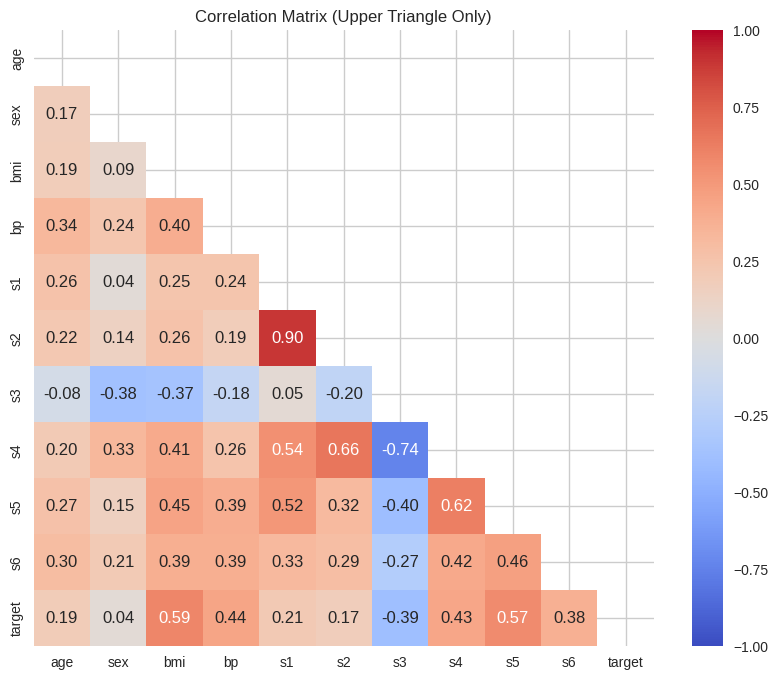

In [101]:
corr = df.corr(numeric_only=True)

# Mask lower triangle (including diagonal)
mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Matrix (Upper Triangle Only)")
plt.show()

- Remember not to drop columns just yet just loosely be aware they maybe be a possibility of dropping some collinear columns later in the train,test split.

comments:

possible actions:

- Redundant information
- possibility that drops will be made later?

### 6. Outliers & Anomalies

Are outliers real or errors?

- Errors hurt model, uses domain knowledge to determine this and decide whether to remove or handle them.
  e.g. height of 5 year old is being 7 feet like tall is likely an error
- Meaningful extremes are important e.g. very high incomes because you want see how your model performs on the full ranges of scenarios it'd enouter in production.

In [102]:
# IQR-based outlier count per column
numeric_data = df.select_dtypes(include='number')

Q1 = numeric_data.quantile(0.25,numeric_only=True)
Q3 = numeric_data.quantile(0.75,numeric_only=True)
IQR = Q3 - Q1

outliers = ((numeric_data < (Q1 - 1.5 * IQR)) | (numeric_data > (Q3 + 1.5 * IQR))).sum()
outliers.sort_values(ascending=False)

s6        9
s1        8
s3        7
s2        7
s5        4
bmi       3
s4        2
sex       0
age       0
bp        0
target    0
dtype: int64

comments:

possible considerations

Do extreme values exist that could:
- distort model learning?
- inflate error metrics? (consider especially if the outlier are in the target)

Are outliers:
- genuine signal (e.g. high-value customers)?
- or data issues?

## We have now our EDA

# Train/Test Split

In [103]:
from sklearn.model_selection import train_test_split

X = df.drop(["target"],axis=1)
y = df["target"]

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

# Modelling

create a baseline model:

In [104]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error
import numpy as np

In [105]:
# Mean baseline
dummy_mean = DummyRegressor(strategy="mean")
dummy_mean.fit(X_train, y_train)

y_pred_mean = dummy_mean.predict(X_test)

print("MEAN BASELINE")
#print("MAE:", mean_absolute_error(y_test, y_pred_mean))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_mean)))

MEAN BASELINE
RMSE: 73.22249283682244


Interpretation

In the context of the baseline model a RMSE of 73.22 means

If you always predict the average, you’ll be wrong by ~73 units.

Your goal now:

build models that materially reduce this number.

In [106]:
from pycaret.regression import *

In [107]:
exp_setup = setup(data=X, target=y, session_id=123 , fold=5, n_jobs=1, train_size=0.8)

,Description,Value
0,Session id,123
1,Target,target
2,Target type,Regression
3,Original data shape,"(442, 11)"
4,Transformed data shape,"(442, 11)"
5,Transformed train set shape,"(353, 11)"
6,Transformed test set shape,"(89, 11)"
7,Numeric features,10
8,Preprocess,True
9,Imputation type,simple


## Interpreting The Preprocessing Steps From Output

Look at the orignal data shape and the transformed data shape:

how many more columns were added (if any)?
which transformation step increased the columns count? (ignore if columns the same):
  
- scaling?
- label_encoding?
- one hot encoding?
  

Look at the imputation types used to handle missing values:

- For missing numerical features which imputation method was used?
- what the problem with this approach?

Look at the categorical imputation types:

- which method was being used?

which case does the mean imputation not make sense:
- if the column contains outliers the mean can be distorted
- we should default to the median instead always
- we use the median imputation instead if outliers are present

Stratified K was not used, why wasn't it neccessary in the Regression Scenario?

In [108]:
best_model = compare_models( budget_time = 1)

,Model,MAE,MSE,RMSE,R2,RMSLE,MAPE,TT (Sec)
lr,Linear Regression,45.1328,3100.9479,55.6213,0.4582,0.4299,0.4055,0.0080
br,Bayesian Ridge,45.4632,3124.9388,55.8304,0.4550,0.4268,0.4079,0.0080
huber,Huber Regressor,45.4812,3160.4138,56.1560,0.4467,0.4305,0.4062,0.0140
et,Extra Trees Regressor,47.0907,3314.6270,57.5122,0.4228,0.4376,0.4202,0.0600
ada,AdaBoost Regressor,46.8969,3330.7785,57.6024,0.4219,0.4412,0.4343,0.0440
par,Passive Aggressive Regressor,48.1833,3377.8183,57.9755,0.4164,0.4398,0.4297,0.0060
rf,Random Forest Regressor,47.7332,3399.9426,58.2724,0.4043,0.4414,0.4234,0.1080
ridge,Ridge Regression,50.1393,3568.2142,59.5424,0.3846,0.4532,0.4600,0.0100
gbr,Gradient Boosting Regressor,49.4456,3635.2602,60.2638,0.3638,0.4520,0.4330,0.0520
knn,K Neighbors Regressor,47.9527,3689.7431,60.5643,0.3632,0.4493,0.4146,0.0060


our class is imbalanced so like accuracy the AUC/F1 is not reliable rather. Instead we select base on the metric that aligns with our business problem ***

# Interpreting The RMSE Of The Best Model

For your best model and it RMSE

Example, our model model RMSE = 55.6213:

“Our model achieves an RMSE of 55.6213, meaning predictions are typically within ±55.6 units of the true value, improving on the baseline error of 73 by ~23%.”

# Hyperparameter tuning

suppose you want to attempt to improve your model you can run 

the code below 

In [109]:
# Tune the hyperparameters of the best model
tuned_model = tune_model(best_model)

# Let's look at the parameters now. Notice how they have changed from the baseline!
print("\n--- Tuned Model Parameters ---")
print(tuned_model)

,MAE,MSE,RMSE,R2,RMSLE,MAPE
Fold,,,,,,
0,45.8121,3234.4355,56.8721,0.3660,0.4353,0.4044
1,47.7423,3493.9722,59.1098,0.4558,0.4922,0.5028
2,41.4179,2653.9578,51.5166,0.5177,0.4017,0.3509
3,47.1962,3241.2290,56.9318,0.5349,0.4128,0.3850
4,43.4954,2881.1448,53.6763,0.4165,0.4075,0.3843
Mean,45.1328,3100.9479,55.6213,0.4582,0.4299,0.4055
Std,2.3669,296.6747,2.6864,0.0627,0.0332,0.0516


Fitting 5 folds for each of 2 candidates, totalling 10 fits
Original model was better than the tuned model, hence it will be returned. NOTE: The display metrics are for the tuned model (not the original one).

--- Tuned Model Parameters ---
LinearRegression(n_jobs=1)


# Baseline Model And Tuning Attempt Done ✅

as you noticed the tuned model doesn't improve upon the baseline, we will see how we can improve upon the pycaret model in the optional drop in

# Evaluate On Test Set

lets get the metrics for the evaluation on the test set

In [110]:
preds = predict_model(tuned_model)

,Model,MAE,MSE,RMSE,R2,RMSLE,MAPE
0,Linear Regression,42.8761,2724.2578,52.1944,0.5676,0.3973,0.3761


let see what how our model made its predictions

comment on the performance in terms of the rmse:

# Saving your model

In [112]:
# finalize for production
final_model = finalize_model(tuned_model)

# save
save_model(final_model, 'my_model')

Transformation Pipeline and Model Successfully Saved


(Pipeline(memory=Memory(location=None),
          steps=[('numerical_imputer',
                  TransformerWrapper(include=['age', 'sex', 'bmi', 'bp', 's1',
                                              's2', 's3', 's4', 's5', 's6'],
                                     transformer=SimpleImputer())),
                 ('categorical_imputer',
                  TransformerWrapper(include=[],
                                     transformer=SimpleImputer(strategy='most_frequent'))),
                 ('actual_estimator', LinearRegression(n_jobs=1))]),
 'my_model.pkl')

# Further Considerations (To covered in the optional session)

in the optional session we will show you how BEAT the Pycaret model by modifying the preprocessing steps and include manual hyperparameter tuning